# Understanding the image-neural dataloader

This tutorial follows one presentation from the raw MATLAB raster to the tensor returned by `NeuralInputDataset`. It answers two concrete questions:

1. **Does the image paired with a trial have the correct identity?**
2. **Is the neural target exactly the response in the raster after the requested channel selection, time crop, and temporal binning?**
3. **After averaging repetitions, do the neural and saved DNN representations show the expected static-to-dynamic association?**

The repeated `raster` is used here, not `natraster`. Each sample is therefore one presentation of an image; different repetitions of the same image remain separate samples.

> Important: values in this raster are continuous, signed, preprocessed multi-unit responses. They are not binary spike events. The plots below therefore show response values, not spike ticks.

## Axis ledger

The same response changes axis order as it moves through the pipeline:

| Stage | Shape | Meaning |
|---|---|---|
| raw HDF5 `rasters` | `[trials, source_time, source_channels]` | one row per presentation at the original sampling rate |
| `load_img_raster(...).get_array()` | `[neurons, time, trials]` | cropped, area-selected, optionally binned response |
| `NeuralInputDataset[trial][1]` | `[time, neurons]` | target for one presentation |
| one DataLoader target batch | `[batch, time, neurons]` | stacked presentation targets |

The dataset does **not** average repetitions or fit normalization statistics itself. This tutorial optionally preprocesses the `[neurons, time, trials]` array before passing it to `NeuralInputDataset`; the dataset then only applies `transpose(2, 1, 0)` and converts to `float32`.

In [1]:
import os
import sys
from dataclasses import dataclass
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from torchvision import transforms
from torchvision.datasets import ImageFolder

# Locate the repository whether Jupyter starts at the root or scripts/.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [cwd, *cwd.parents] if (path / "config.yaml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project config.yaml.")
# end if the project root is unavailable

ENV = os.getenv("MY_ENV", "tiziano_mac_mini")
with open(PROJECT_ROOT / "config.yaml", "r") as file:
    config = yaml.safe_load(file)
# end with project configuration
paths = config[ENV]["paths"]
sys.path.append(paths["src_path"])
sys.path.append(paths["useful_stuff_path"])

from project_specific_utils.dataloader import (  # noqa: E402
    BrainAreas,
    NeuralInputDataset,
    apply_neural_preprocessing,
    fit_neural_preprocessing,
    load_img_natraster,
    load_img_raster,
    make_neural_input_loader,
    map_image_order_from_ann_to_monkey,
    map_trial_image_order_to_ann,
)
from IT_recap.hf_feature_extraction import load_hf_layer_features  # noqa: E402
from IT_recap.neural_prediction_training import (  # noqa: E402
    split_half_reliability,
)
from IT_recap.static_drsa import compute_static_drsa  # noqa: E402

In [2]:
@dataclass
class Cfg:
    # Repeated single-trial neural data.
    monkey_name: str = "three0"
    brain_area: str = "AIT"
    raster_file: str = "rasters_three0_250313to21.mat"
    raster_key: str = "rasters"
    image_names_file: str = "allimages_three0_250313to21.mat"
    image_names_key: str = "allimages"
    original_fs: int = 1000
    new_fs: int = 100
    time_start_ms: float = 0.0
    time_end_ms: float = 300.0
    raster_chunk_size: int = 512

    # Optional target preprocessing fitted across tutorial samples.
    center_neural_features: bool = False
    robust_minmax_neurons: bool = False
    robust_percentile_range: tuple[float, float] = (1.0, 99.0)
    clip_robust_minmax: bool = True

    # Image source used by the ANN and by the paired dataset.
    folder_name: str = "talia_20each_tizi"

    # Select an image explicitly, or use the strongest repeated response.
    example_image: int | str | None = "camera_04.jpg"
    example_repetition_index: int = 0
    n_high_activity_images_to_list: int = 10
    example_neuron_index: int = 0  # local index within brain_area
    batch_size: int = 8
    n_example_repetitions: int = 4
    n_consistent_channels: int = 5
    self_consistency_resamples: int = 40
    validation_fraction: float = 0.2
    random_seed: int = 0

    # Optional averaged-response comparison at the end.
    natraster_date: str = "250313"

    # Static DNN layers compared with the averaged dynamic neural response.
    model_name: str = "dino_v3_l"
    model_img_size: int = 224
    model_pooling: str = "mean"
    model_layer_names: tuple[str, ...] = (
        "layer.3.mlp.down_proj",
        "layer.13.mlp.down_proj",
        "layer.16.mlp.down_proj",
        "layer.20.mlp.down_proj",
    )
    training_input_mode: str = "activations"
    model_batch_size: int = 64
    signal_RDM_metric: str = "cosine_cnt"
    model_RDM_metric: str = "cosine_cnt"
    RSA_metric: str = "spearman"
    alignment_shuffle_seed: int = 0
    heatmap_cmap: str = "viridis"
    layer_line_cmap: str = "turbo"


cfg = Cfg()
cfg

Cfg(monkey_name='three0', brain_area='AIT', raster_file='rasters_three0_250313to21.mat', raster_key='rasters', image_names_file='allimages_three0_250313to21.mat', image_names_key='allimages', original_fs=1000, new_fs=100, time_start_ms=0.0, time_end_ms=300.0, raster_chunk_size=512, center_neural_features=False, robust_minmax_neurons=False, robust_percentile_range=(1.0, 99.0), clip_robust_minmax=True, folder_name='talia_20each_tizi', example_image='camera_04.jpg', example_repetition_index=0, n_high_activity_images_to_list=10, example_neuron_index=0, batch_size=8, n_example_repetitions=4, n_consistent_channels=5, self_consistency_resamples=40, validation_fraction=0.2, random_seed=0, natraster_date='250313', model_name='dino_v3_l', model_img_size=224, model_pooling='mean', model_layer_names=('layer.3.mlp.down_proj', 'layer.13.mlp.down_proj', 'layer.16.mlp.down_proj', 'layer.20.mlp.down_proj'), training_input_mode='activations', model_batch_size=64, signal_RDM_metric='cosine_cnt', model_RD

## 1. Inspect the source files without loading the full raster

MATLAB v7.3 files are HDF5 files. The repeated response file is stored as `[trials, time, channels]`; the companion file contains one image filename for every trial. This first check is deliberately independent of the project loader.

In [3]:
data_dir = Path(paths["data_path"]) / "data"
raster_path = data_dir / cfg.raster_file
image_names_path = data_dir / cfg.image_names_file

with h5py.File(raster_path, "r") as h5file:
    raw_shape = h5file[cfg.raster_key].shape
    raw_dtype = h5file[cfg.raster_key].dtype
# end with raw raster file

with h5py.File(image_names_path, "r") as h5file:
    image_name_shape = h5file[cfg.image_names_key].shape
# end with image-name file

if raw_shape[0] != image_name_shape[0]:
    raise ValueError("The raw trials and per-trial image names do not align.")
# end if the source files disagree

print(f"raw raster [trials, source_time, source_channels]: {raw_shape}")
print(f"raw dtype: {raw_dtype}")
print(f"per-trial image names: {image_name_shape}")

raw raster [trials, source_time, source_channels]: (14840, 500, 383)
raw dtype: float32
per-trial image names: (14840, 1)


## 2. Load the repeated raster

`load_img_raster` performs four scientifically relevant operations:

1. crops the source time axis;
2. selects and concatenates the channel ranges assigned to the requested brain area;
3. averages non-overlapping temporal bins when `new_fs < original_fs`;
4. changes the axis order to `[neurons, time, trials]`.

For 1000 → 100 Hz, every output value is the mean of 10 consecutive source samples. Cropping happens before binning.

The configuration can additionally center every `(neuron, time-bin)` feature across samples and robustly min-max scale each neuron using percentiles pooled across time and samples. Centering is applied first. This tutorial fits on all loaded samples for visualization; a predictive experiment should fit on training samples only, as done in `noise_layer_baseline_model_dev.ipynb`.

In [4]:
raster, trial_image_names = load_img_raster(
    paths=paths,
    monkey_name=cfg.monkey_name,
    raster_file=cfg.raster_file,
    image_names_file=cfg.image_names_file,
    raster_key=cfg.raster_key,
    image_names_key=cfg.image_names_key,
    original_fs=cfg.original_fs,
    new_fs=cfg.new_fs,
    time_start_ms=cfg.time_start_ms,
    time_end_ms=cfg.time_end_ms,
    brain_area=cfg.brain_area,
    chunk_size=cfg.raster_chunk_size,
)
raw_raster_array = raster.get_array()
neural_preprocessing_stats = fit_neural_preprocessing(
    raw_raster_array,
    center_features=cfg.center_neural_features,
    robust_minmax_neurons=cfg.robust_minmax_neurons,
    robust_percentile_range=cfg.robust_percentile_range,
    clip_robust_minmax=cfg.clip_robust_minmax,
)
raster_array = apply_neural_preprocessing(
    raw_raster_array,
    neural_preprocessing_stats,
)

if len(trial_image_names) != raster_array.shape[2]:
    raise ValueError("Every loaded neural trial must have one image name.")
# end if trial metadata and responses disagree

print(f"loaded raster [neurons, time, trials]: {raster_array.shape}")
print(
    "neural preprocessing: "
    f"center_features={cfg.center_neural_features}, "
    f"robust_minmax_neurons={cfg.robust_minmax_neurons}, "
    f"percentiles={cfg.robust_percentile_range}"
)
print(f"loaded sampling frequency: {raster.fs} Hz")
print(f"first five source image names: {trial_image_names[:5]}")
print(f"unique stimuli: {len(set(trial_image_names))}")

loaded raster [neurons, time, trials]: (25, 30, 14840)
neural preprocessing: center_features=False, robust_minmax_neurons=False, percentiles=(1.0, 99.0)
loaded sampling frequency: 100 Hz
first five source image names: ['easteregg_redo_14.jpg', 'tablesmall_08.jpg', 'coin_01.jpg', 'familiarObjects_100.jpg', 'breadloaf_07.jpg']
unique stimuli: 776


In [12]:
raster.shape()
len(trial_image_names)

14840

In [20]:
neuron_average_t_course = np.mean(raster.array, axis=2)[:, :, np.newaxis]
sse_lower_bound = np.sum((raster.array - neuron_average_t_course)**2)
mse_lower_bound = sse_lower_bound/raster.array.size


In [23]:
responses = raster.array
trial_image_names = np.asarray(trial_image_names)
assert raster.shape()[2] == len(trial_image_names)
unique_images = np.unique(trial_image_names)

# Store the optimal image-specific prediction for every trial.
optimal_prediction = np.empty_like(responses, dtype=float)

for image_name in unique_images:
    image_mask = trial_image_names == image_name

    # Average across repetitions of this image: (neurons, time).
    image_average_timecourse = np.mean(
        raster.array[:, :, image_mask],
        axis=2,
    )
    # Assign the average time course to every repetition of the image.
    optimal_prediction[:, :, image_mask] = (
        image_average_timecourse[:, :, np.newaxis]
    )
# end for image_name
squared_errors = (raster.array - optimal_prediction) ** 2

sse_upper_bound = np.sum(squared_errors)
mse_upper_bound = np.mean(squared_errors)

In [27]:
mse_range = mse_lower_bound - mse_upper_bound
print(mse_range)

0.04382694715253177


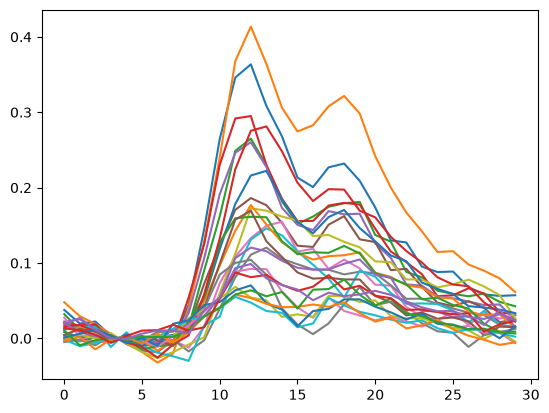

In [ ]:
plt.plot(neuron_average_t_course.T);

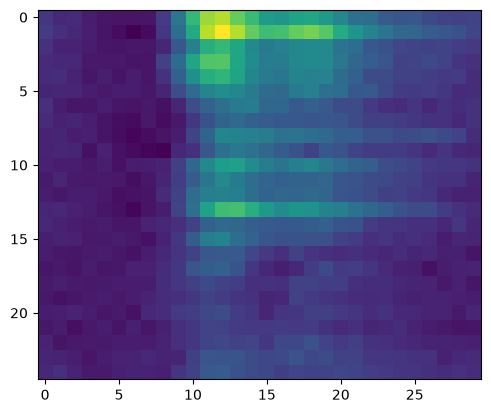

In [32]:
plt.imshow(np.mean(raster, axis=2).T)

## 3. Map each neural trial to the correct image

`ImageFolder` defines the source order used when images or saved ANN activations are indexed. Neural trials occur in a different order and contain repetitions.

`image_indices[trial_index]` is therefore the `ImageFolder` row for that neural trial. Repeated occurrences of one stimulus have the same image index but different neural targets. The mapping uses filenames, not class labels.

This tutorial uses only `ToTensor()` so the paired image can be displayed directly. Replace that transform with the model-specific resize and normalization when training; doing so changes the image tensor but not its neural pairing.

Set `cfg.example_image` to an `ImageFolder` index or a quoted filename to inspect a specific image. With a value of `None`, the notebook ranks repeated images by the RMS magnitude of their repetition-averaged population response and selects the strongest one. The printed candidate table provides both indices and filenames. `cfg.example_repetition_index` selects which presentation supplies the single-trial audit.